In [8]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import random

In [9]:
from datasets import load_dataset
print("Hugging Face Datasets imported successfully")

Hugging Face Datasets imported successfully


## 2. Dataset Selection and Inspection

Dataset: PtBrVId
Source: Hugging Face (LIAAD)

Objective:
Inspect the dataset configurations, available splits,
features, labels, and metadata before loading the data.

In [10]:
from datasets import get_dataset_config_names, load_dataset_builder

dataset_name = 'liaad/PtBrVId'

configs = get_dataset_config_names(dataset_name)
print("available configuration")
for config in configs: 
    print("-", config)

available configuration
- journalistic
- legal
- literature
- politics
- social_media
- web


In [11]:
for config in configs:

    print(f"\n{'='*50}")
    print(f"CONFIGURATION: {config}")
    print(f"{'='*50}")

    builder = load_dataset_builder(
        dataset_name,
        name=config
    )

    print("\nFeatures:")
    print(builder.info.features)

    print("\nAvailable splits:")
    print(builder.info.splits)

    print("\nDescription:")
    print(builder.info.description[:500])
    


CONFIGURATION: journalistic

Features:
{'text': Value('string'), 'label': Value('int64')}

Available splits:
{'train': SplitInfo(name='train', num_bytes=1165926359, num_examples=1776290, shard_lengths=[707097, 706097, 363096], dataset_name='pt_br_v_id'), 'valid': SplitInfo(name='valid', num_bytes=571756, num_examples=1000, dataset_name='pt_br_v_id'), 'test': SplitInfo(name='test', num_bytes=28287, num_examples=35, dataset_name='pt_br_v_id')}

Description:


CONFIGURATION: legal

Features:
{'text': Value('string'), 'label': Value('int64')}

Available splits:
{'train': SplitInfo(name='train', num_bytes=860024088, num_examples=2961596, shard_lengths=[1726798, 1234798], dataset_name='pt_br_v_id'), 'valid': SplitInfo(name='valid', num_bytes=282364, num_examples=1000, dataset_name='pt_br_v_id'), 'test': SplitInfo(name='test', num_bytes=10390, num_examples=37, dataset_name='pt_br_v_id')}

Description:


CONFIGURATION: literature

Features:
{'text': Value('string'), 'label': Value('int64')}



## 3. Initial Dataset Exploration

We will inspect the validation split of each domain.

Objectives:
- Examine class distribution.
- Identify the mapping between numerical labels and varieties.
- Inspect representative text samples.

In [12]:
from datasets import load_dataset

dataset_samples = {}

for config in configs:

    print(f"\n{'='*60}")
    print(f"DOMAIN: {config.upper()}")
    print(f"{'='*60}")

    # Load only the validation split
    dataset = load_dataset(
        dataset_name,
        name=config,
        split="valid"
    )

    dataset_samples[config] = dataset

    df = dataset.to_pandas()

    print("\nDataset shape:", df.shape)

    print("\nLabel distribution:")
    print(df["label"].value_counts().sort_index())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nRepresentative examples:")

    for label in sorted(df["label"].unique()):

        sample = df[df["label"] == label].iloc[0]

        print(f"\nLabel: {label}")


DOMAIN: JOURNALISTIC

Dataset shape: (1000, 2)

Label distribution:
label
0    500
1    500
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64

Representative examples:

Label: 0

Label: 1

DOMAIN: LEGAL

Dataset shape: (1000, 2)

Label distribution:
label
0    500
1    500
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64

Representative examples:

Label: 0

Label: 1

DOMAIN: LITERATURE

Dataset shape: (1000, 2)

Label distribution:
label
0    500
1    500
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64

Representative examples:

Label: 0

Label: 1

DOMAIN: POLITICS

Dataset shape: (1000, 2)

Label distribution:
label
0    500
1    500
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64

Representative examples:

Label: 0

Label: 1

DOMAIN: SOCIAL_MEDIA

Dataset shape: (1000, 2)

Label distribution:
label
0    500
1    500
Name: count, dtype: int64

Missing values:
text     

In [13]:
domain_summary = []

for config, dataset in dataset_samples.items():
    df = dataset.to_pandas()
    counts = df["label"].value_counts()

    domain_summary.append({
        "domain": config,
        "total_samples": len(df),
        "label_0": counts.get(0, 0),
        "label_1": counts.get(1, 0),
        "missing_text": df["text"].isna().sum(),
        "duplicate_text": df["text"].duplicated().sum(),
        "avg_text_length": df["text"].str.len().mean()
    })

summary_df = pd.DataFrame(domain_summary)
summary_df

,domain,total_samples,label_0,label_1,missing_text,duplicate_text,avg_text_length
0,journalistic,1000,500,500,0,0,559.631
1,legal,1000,500,500,0,0,270.239
2,literature,1000,500,500,0,0,389.050
3,politics,1000,500,500,0,0,1475.133
4,social_media,1000,500,500,0,0,97.060
5,web,1000,500,500,0,0,2826.684


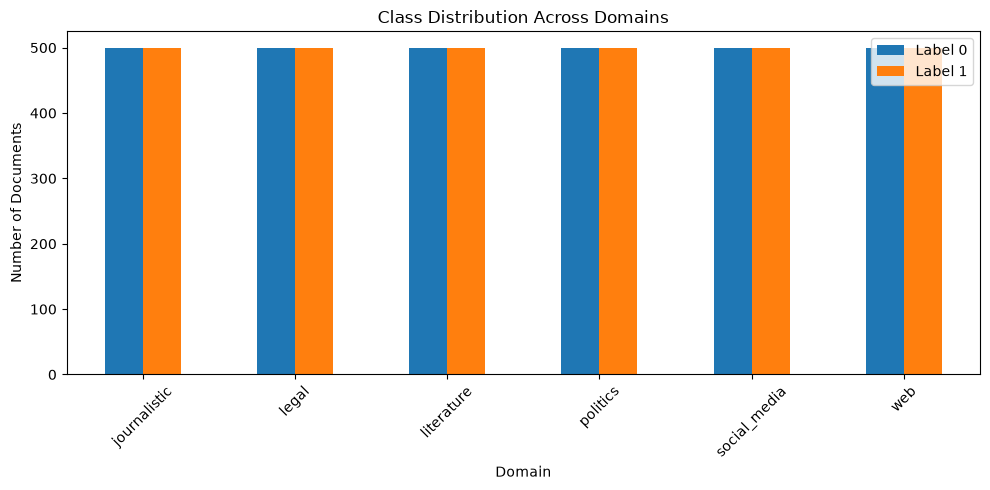

In [14]:
summary_df.set_index("domain")[["label_0", "label_1"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Class Distribution Across Domains")
plt.xlabel("Domain")
plt.ylabel("Number of Documents")
plt.xticks(rotation=45)
plt.legend(["Label 0", "Label 1"])
plt.tight_layout()
plt.show()